# Tasks 1, 2 & 3: Setup, Baseline Generation, and SFT Training

**Kaggle settings before you run:** Accelerator = GPU T4 x2, Internet = ON.

**Layout assumed:** `src/core.py` and a root-level `submission_adapter.py` are pushed to your fork, and the fork is **public** (Cell 1 clones without credentials).

**Order matters:** Cell 5.5 (baseline generation) must run *before* the training cell, because it uses the untouched base model.

**Workflow:**
1. Set `GITHUB_USER` in Cell 1.
2. Run all cells once with `debug=True` in Cell 3 (about 5-10 min, mostly dataset and model downloads) to verify everything works.
3. Set `debug=False` in Cell 3, then **Save Version -> Save & Run All (Commit)**.

**Afterwards:** download `alpaca_eval_300_seed42.json` and commit it to `eval_sets/` in your repo. Later notebooks must use that exact file.


In [1]:
# Cell 1: Clone your fork and install deps (do NOT reinstall torch)
import os
GITHUB_USER = 'saad-hammad'  # <-- CHANGE THIS to your GitHub username
REPO_NAME = 'small-model-alignment-starter'
REPO_DIR = f'/kaggle/working/{REPO_NAME}'

os.chdir('/kaggle/working')
!rm -rf {REPO_NAME}
!git clone https://github.com/{GITHUB_USER}/{REPO_NAME}.git
os.chdir(REPO_DIR)

!python -m pip uninstall -y -q torchao || true
!python -m pip install -q 'transformers>=4.43.0,<5' 'datasets>=2.18,<5' huggingface_hub accelerate tqdm pyyaml sentencepiece safetensors pytest matplotlib
!python -m pip install -q -e . --no-deps
!nvidia-smi

Cloning into 'small-model-alignment-starter'...
remote: Enumerating objects: 336, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 336 (delta 11), reused 14 (delta 10), pack-reused 314 (from 1)
Receiving objects: 100% (336/336), 1.07 MiB | 35.25 MiB/s, done.
Resolving deltas: 100% (186/186), done.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 109.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 31.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 99.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires hugg

In [2]:
# Cell 2: Versions, GPU check, and public adapter smoke tests (Task 1)
import sys, torch, transformers, datasets
sys.path.insert(0, REPO_DIR)
print('torch', torch.__version__, '| transformers', transformers.__version__, '| datasets', datasets.__version__)
print('GPUs visible:', torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(' ', i, torch.cuda.get_device_name(i), round(torch.cuda.get_device_properties(i).total_memory / 2**30, 1), 'GiB')

assert os.path.exists(f'{REPO_DIR}/src/core.py'), 'src/core.py not found in the clone: did you push it to your fork?'
assert os.path.exists(f'{REPO_DIR}/submission_adapter.py'), 'submission_adapter.py not found: did you push it?'
!PYTHONPATH=. python -m pytest -v tests/test_public_adapter_smoke.py

torch 2.11.0+cu128 | transformers 4.57.6 | datasets 4.8.5
GPUs visible: 2
  0 Tesla T4 14.6 GiB
  1 Tesla T4 14.6 GiB
============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /kaggle/working/small-model-alignment-starter
configfile: pyproject.toml
plugins: typeguard-4.6.0, anyio-4.14.2, langsmith-0.12.1
collected 7 items                                                              

tests/test_public_adapter_smoke.py::test_required_functions_have_the_documented_signatures PASSED [ 14%]
tests/test_public_adapter_smoke.py::test_sft_batch_masks_prompt_and_padding_and_includes_eos PASSED [ 28%]
tests/test_public_adapter_smoke.py::test_response_logprobs_are_one_value_per_row_and_response_only PASSED [ 42%]
tests/test_public_adapter_smoke.py::test_sft_loss_uses_an_accepted_reduction_and_has_policy_gradients PASSED [ 57%]
tests/test_public_adapter_smoke.py:

In [3]:
# Cell 3: Config, seeds, and prompt template
import sys, json, math, random, time
import numpy as np

# core.py lives in src/ in this repo
sys.path.insert(0, REPO_DIR)
try:
    from src import core
except ImportError:
    sys.path.insert(0, f'{REPO_DIR}/src')
    import core
print('core loaded from:', core.__file__)

CFG = dict(
    model_name='Qwen/Qwen2.5-0.5B',
    debug=False,                 # <-- Set False for the real 30k run
    seed=42,
    n_train=30000, n_val=1000,
    n_alpaca_eval=300,
    max_length=512, max_prompt_chars=1500,
    micro_bs=2, grad_accum=16,  # effective batch size 32
    lr=2e-5, warmup_frac=0.03, weight_decay=0.1, clip=1.0, epochs=1,
    eval_every=100, log_every=10,
)
if CFG['debug']:
    CFG.update(n_train=320, n_val=64, n_alpaca_eval=10, eval_every=5, log_every=1)

RUN_NAME = 'sft_debug' if CFG['debug'] else 'sft'
OUT_DIR = f'/kaggle/working/outputs/{RUN_NAME}'
os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG['seed'])

# Prompt template: reuse this EXACT function for SFT, DPO, and evaluation generation.
def format_prompt(instruction):
    return '### Instruction:\n' + instruction.strip() + '\n\n### Response:\n'

print(json.dumps(CFG, indent=1))

core loaded from: /kaggle/working/small-model-alignment-starter/src/core.py
{
 "model_name": "Qwen/Qwen2.5-0.5B",
 "debug": false,
 "seed": 42,
 "n_train": 30000,
 "n_val": 1000,
 "n_alpaca_eval": 300,
 "max_length": 512,
 "max_prompt_chars": 1500,
 "micro_bs": 2,
 "grad_accum": 16,
 "lr": 2e-05,
 "warmup_frac": 0.03,
 "weight_decay": 0.1,
 "clip": 1.0,
 "epochs": 1,
 "eval_every": 100,
 "log_every": 10
}


In [4]:
# Cell 4: Build Single-turn UltraChat SFT splits (30k train / 1k val)
from datasets import load_dataset
raw_train = load_dataset('HuggingFaceH4/ultrachat_200k', split='train_sft')
raw_val = load_dataset('HuggingFaceH4/ultrachat_200k', split='test_sft')

def to_pair(ex):
    msgs = ex['messages']
    if len(msgs) < 2 or msgs[0]['role'] != 'user' or msgs[1]['role'] != 'assistant':
        return None
    p, r = msgs[0]['content'].strip(), msgs[1]['content'].strip()
    if not p or not r or len(p) > CFG['max_prompt_chars']:
        return None
    return {'prompt': format_prompt(p), 'response': r}

def build_pairs(ds, n, seed):
    idx = list(range(len(ds)))
    random.Random(seed).shuffle(idx)
    out = []
    for i in idx:
        pr = to_pair(ds[i])
        if pr is not None:
            out.append(pr)
        if len(out) >= n:
            break
    return out

train_pairs = build_pairs(raw_train, CFG['n_train'], CFG['seed'])
val_pairs = build_pairs(raw_val, CFG['n_val'], CFG['seed'])
print('train', len(train_pairs), '| val', len(val_pairs))

json.dump(train_pairs, open(f'{OUT_DIR}/train_pairs.json', 'w'))
json.dump(val_pairs, open(f'{OUT_DIR}/val_pairs.json', 'w'))
print(train_pairs[0]['prompt'][:300])

README.md: 0.00B [00:00, ?B/s]

data/train_sft-00000-of-00003-a3ecf92756(…):   0%|          | 0.00/244M [00:00<?, ?B/s]

data/train_sft-00001-of-00003-0a1804bcb6(…):   0%|          | 0.00/244M [00:00<?, ?B/s]

data/train_sft-00002-of-00003-ee46ed25cf(…):   0%|          | 0.00/244M [00:00<?, ?B/s]

data/test_sft-00000-of-00001-f7dfac4afe5(…):   0%|          | 0.00/81.2M [00:00<?, ?B/s]

...

Generating train_sft split:   0%|          | 0/207865 [00:00<?, ? examples/s]

Generating test_sft split:   0%|          | 0/23110 [00:00<?, ? examples/s]

Generating train_gen split:   0%|          | 0/256032 [00:00<?, ? examples/s]

Generating test_gen split:   0%|          | 0/28304 [00:00<?, ? examples/s]

train 30000 | val 1000
### Instruction:
Develop a rom-com screenplay about two people from very different backgrounds falling in love.

### Response:



In [5]:
# Cell 5: Load Base Model + Tokenizer + Mask Sanity Check
from transformers import AutoTokenizer, AutoModelForCausalLM
device = torch.device('cuda:0')
tokenizer = AutoTokenizer.from_pretrained(CFG['model_name'])
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
model = AutoModelForCausalLM.from_pretrained(
    CFG['model_name'], torch_dtype=torch.float32, attn_implementation='sdpa'
).to(device)
model.config.use_cache = False  # generation helper switches it on temporarily

print(f'EOS {tokenizer.eos_token!r} id={tokenizer.eos_token_id} | PAD {tokenizer.pad_token!r} id={tokenizer.pad_token_id}')
print('params (M):', round(sum(p.numel() for p in model.parameters()) / 1e6, 1))

b = core.build_sft_batch(tokenizer, [train_pairs[0]['prompt']], [train_pairs[0]['response']], CFG['max_length'])
lab = b['labels'][0]
sup = lab != -100
print('supervised tokens:', sup.sum().item(), 'of', lab.numel())
print('first supervised tokens decode to:', repr(tokenizer.decode(b['input_ids'][0][sup][:30])))

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

EOS '<|endoftext|>' id=151643 | PAD '<|endoftext|>' id=151643
params (M): 494.0
supervised tokens: 490 of 512
first supervised tokens decode to: 'Title: Love Across the Divide\n\nAct 1:\n\nWe meet our protagonist, AMELIA, a successful advertising executive in her mid-30'


In [6]:
# Cell 5.5: Task 2 - Baseline generation on a fixed 300-prompt AlpacaEval subset (seed=42)
# Must run BEFORE training: the model here is still the untouched base model.
from tqdm.auto import tqdm

ALPACA_URL = 'https://huggingface.co/datasets/tatsu-lab/alpaca_eval/resolve/main/alpaca_eval.json'
alpaca_ds = load_dataset('json', data_files=ALPACA_URL, split='train')
print('AlpacaEval size:', len(alpaca_ds), '| columns:', alpaca_ds.column_names)

alpaca_idx = list(range(len(alpaca_ds)))
random.Random(42).shuffle(alpaca_idx)
alpaca_subset = [
    {'id': f'alpaca_{i}', 'instruction': alpaca_ds[i]['instruction'], 'dataset': 'alpaca_eval'}
    for i in alpaca_idx[:300]
]
os.makedirs(f'{REPO_DIR}/eval_sets', exist_ok=True)
json.dump(alpaca_subset, open(f'{REPO_DIR}/eval_sets/alpaca_eval_300_seed42.json', 'w'), indent=2)
json.dump(alpaca_subset, open(f'{OUT_DIR}/alpaca_eval_300_seed42.json', 'w'), indent=2)

# Decoding settings: use the SAME settings (and this same function) for SFT and DPO generation.
GEN_KW = dict(do_sample=False, repetition_penalty=1.1, max_new_tokens=256)


@torch.no_grad()
def generate_responses(model, tokenizer, instructions, bs=16, **gen_kw):
    """Greedy batched generation with left padding. Returns one string per instruction, in order."""
    was_training = model.training
    old_side, old_cache = tokenizer.padding_side, model.config.use_cache
    model.eval()
    tokenizer.padding_side = 'left'
    model.config.use_cache = True
    order = sorted(range(len(instructions)), key=lambda i: len(instructions[i]))  # less padding
    outs = [None] * len(instructions)
    for s in tqdm(range(0, len(order), bs), desc='generate'):
        idxs = order[s:s + bs]
        enc = tokenizer([format_prompt(instructions[i]) for i in idxs],
                        return_tensors='pt', padding=True).to(model.device)
        with torch.autocast('cuda', dtype=torch.float16):
            gen = model.generate(**enc, eos_token_id=tokenizer.eos_token_id,
                                 pad_token_id=tokenizer.pad_token_id, **gen_kw)
        for j, i in enumerate(idxs):
            outs[i] = tokenizer.decode(gen[j, enc['input_ids'].shape[1]:], skip_special_tokens=True).strip()
    tokenizer.padding_side, model.config.use_cache = old_side, old_cache
    if was_training:
        model.train()
    return outs


eval_slice = alpaca_subset[:CFG['n_alpaca_eval']]
t_gen = time.time()
texts = generate_responses(model, tokenizer, [x['instruction'] for x in eval_slice], bs=16, **GEN_KW)
base_generations = [
    {'id': it['id'], 'instruction': it['instruction'], 'output': txt,
     'generator': 'qwen2.5-0.5b-base', 'dataset': 'alpaca_eval'}
    for it, txt in zip(eval_slice, texts)
]
json.dump(base_generations, open(f'{OUT_DIR}/base_alpaca_eval_generations.json', 'w'), indent=2)
print(f'Saved {len(base_generations)} baseline generations in {(time.time() - t_gen) / 60:.1f} min')

# manual sanity check on 2 samples
for g in base_generations[:2]:
    print('INSTRUCTION:', g['instruction'][:200])
    print('OUTPUT:', g['output'][:400])
    print('-' * 70)


alpaca_eval.json: 0.00B [00:00, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

AlpacaEval size: 805 | columns: ['dataset', 'instruction', 'output', 'generator']


generate:   0%|          | 0/19 [00:00<?, ?it/s]

Saved 300 baseline generations in 3.1 min
INSTRUCTION: What factors would you consider when designing an inclusive and accessible public transportation system?
OUTPUT: When designing an inclusive and accessible public transportation system, several key factors should be considered:

1. **Accessibility**: Ensure that the system is easily navigable for individuals with disabilities or mobility impairments. This includes features such as ramps, elevators, and tactile signage.

2. **Inclusivity**: Make sure the system caters to a wide range of users, including those
----------------------------------------------------------------------
INSTRUCTION: Is a thumb war violent?
OUTPUT: Yes, a thumb war is considered violent. Thumb wars are often characterized by physical aggression and violence towards the other party involved in the conflict. The use of physical force, such as hitting or pushing, can escalate tensions and lead to further escalation of the situation.

Thumb wars can also involve

In [7]:
# Cell 6: Optimizer, scheduler, validation, and checkpoint helpers
from torch.utils.data import DataLoader

decay, no_decay = [], []
for n, p in model.named_parameters():
    (no_decay if ('bias' in n or 'norm' in n) else decay).append(p)
optimizer = torch.optim.AdamW(
    [{'params': decay, 'weight_decay': CFG['weight_decay']},
     {'params': no_decay, 'weight_decay': 0.0}],
    lr=CFG['lr'], betas=(0.9, 0.95),
)

eff_bs = CFG['micro_bs'] * CFG['grad_accum']
total_steps = math.ceil(len(train_pairs) / eff_bs) * CFG['epochs']
warmup_steps = max(1, int(CFG['warmup_frac'] * total_steps))
def lr_lambda(s):
    if s < warmup_steps:
        return (s + 1) / warmup_steps
    prog = (s - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * prog))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
scaler = torch.amp.GradScaler('cuda')
print('optimizer steps:', total_steps, '| warmup steps:', warmup_steps, '| effective batch:', eff_bs)

metrics_path = f'{OUT_DIR}/metrics.jsonl'
open(metrics_path, 'w').close()
def log(rec):
    with open(metrics_path, 'a') as f:
        f.write(json.dumps(rec) + '\n')

def save_ckpt(path):
    os.makedirs(path, exist_ok=True)
    model.save_pretrained(path)
    tokenizer.save_pretrained(path)

@torch.no_grad()
def evaluate(bs=4):
    model.eval()
    tot_nll, tot_tok = 0.0, 0
    for i in range(0, len(val_pairs), bs):
        chunk = val_pairs[i:i + bs]
        batch = core.build_sft_batch(tokenizer, [x['prompt'] for x in chunk], [x['response'] for x in chunk], CFG['max_length'])
        with torch.autocast('cuda', dtype=torch.float16):
            tlp, mask = core._score_response_tokens(model, batch)
        tot_nll += -tlp.sum().item()
        tot_tok += mask.sum().item()
    model.train()
    return tot_nll / max(1, tot_tok)

best_val = float('inf')
def run_eval(step):
    global best_val
    v = evaluate()
    log({'type': 'val', 'step': step, 'val_loss': v})
    print(f'[step {step}] val_loss {v:.4f}')
    if step > 0 and v < best_val:
        best_val = v
        save_ckpt(f'{OUT_DIR}/best')
        print('  -> new best, checkpoint saved')
    return v

optimizer steps: 938 | warmup steps: 28 | effective batch: 32


In [8]:
# Cell 7: SFT Training Loop (~1.5 h for the full 30k run)
loader = DataLoader(
    train_pairs, batch_size=CFG['micro_bs'], shuffle=True,
    collate_fn=lambda b: b, generator=torch.Generator().manual_seed(CFG['seed']),
)
model.train()
optimizer.zero_grad(set_to_none=True)
step, run_loss, run_n = 0, 0.0, 0
t0 = time.time()
run_eval(0)  # baseline val loss before any training

for epoch in range(CFG['epochs']):
    n_batches = len(loader)
    for i, batch in enumerate(loader):
        prompts = [x['prompt'] for x in batch]
        responses = [x['response'] for x in batch]
        with torch.autocast('cuda', dtype=torch.float16):
            loss = core.compute_sft_loss(model, tokenizer, prompts, responses, CFG['max_length'])
        scaler.scale(loss / CFG['grad_accum']).backward()
        run_loss += loss.item()
        run_n += 1

        if (i + 1) % CFG['grad_accum'] == 0 or (i + 1) == n_batches:
            scaler.unscale_(optimizer)
            gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['clip'])
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            step += 1

            if step % CFG['log_every'] == 0:
                tl = run_loss / max(1, run_n)
                lr_now = scheduler.get_last_lr()[0]
                log({'type': 'train', 'step': step, 'train_loss': tl, 'lr': lr_now, 'grad_norm': float(gnorm)})
                print(f'step {step}/{total_steps} | loss {tl:.4f} | lr {lr_now:.2e} | gnorm {float(gnorm):.2f} | {(time.time() - t0) / 60:.1f} min')
                run_loss, run_n = 0.0, 0
            if step % CFG['eval_every'] == 0:
                run_eval(step)

if step % CFG['eval_every'] != 0:
    run_eval(step)  # final eval unless one just ran
save_ckpt(f'{OUT_DIR}/final')
print('done. best val loss:', best_val, '| total minutes:', round((time.time() - t0) / 60, 1))

[step 0] val_loss 1.4242
step 10/938 | loss 1.3421 | lr 7.86e-06 | gnorm 4.21 | 1.6 min
step 20/938 | loss 1.3575 | lr 1.50e-05 | gnorm 4.15 | 2.4 min
step 30/938 | loss 1.4214 | lr 2.00e-05 | gnorm 4.63 | 3.2 min
step 40/938 | loss 1.3530 | lr 2.00e-05 | gnorm 4.20 | 4.1 min
step 50/938 | loss 1.4235 | lr 2.00e-05 | gnorm 3.67 | 4.9 min
step 60/938 | loss 1.3829 | lr 1.99e-05 | gnorm 4.81 | 5.7 min
step 70/938 | loss 1.3944 | lr 1.99e-05 | gnorm 3.99 | 6.6 min
step 80/938 | loss 1.3925 | lr 1.98e-05 | gnorm 3.44 | 7.4 min
step 90/938 | loss 1.4143 | lr 1.98e-05 | gnorm 4.19 | 8.2 min
step 100/938 | loss 1.4099 | lr 1.97e-05 | gnorm 3.62 | 9.1 min
[step 100] val_loss 1.4462
  -> new best, checkpoint saved
step 110/938 | loss 1.3785 | lr 1.96e-05 | gnorm 4.15 | 10.8 min
step 120/938 | loss 1.3958 | lr 1.95e-05 | gnorm 4.16 | 11.6 min
step 130/938 | loss 1.4076 | lr 1.94e-05 | gnorm 4.73 | 12.5 min
step 140/938 | loss 1.4450 | lr 1.93e-05 | gnorm 4.28 | 13.3 min
step 150/938 | loss 1.346

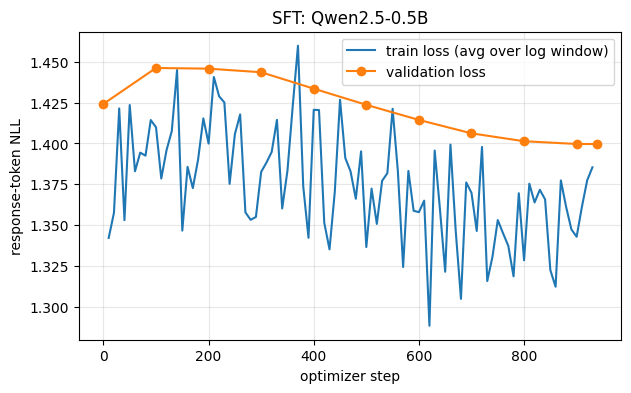

In [9]:
# Cell 8: Plot training & validation loss curves
import matplotlib.pyplot as plt
recs = [json.loads(l) for l in open(metrics_path)]
tr = [r for r in recs if r['type'] == 'train']
va = [r for r in recs if r['type'] == 'val']
plt.figure(figsize=(7, 4))
plt.plot([r['step'] for r in tr], [r['train_loss'] for r in tr], label='train loss (avg over log window)')
plt.plot([r['step'] for r in va], [r['val_loss'] for r in va], 'o-', label='validation loss')
plt.xlabel('optimizer step'); plt.ylabel('response-token NLL'); plt.legend(); plt.grid(alpha=0.3)
plt.title('SFT: Qwen2.5-0.5B')
plt.savefig(f'{OUT_DIR}/sft_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# Cell 9: Sanity generation on 3 prompts (check EOS behavior, format, length)
model.eval()
model.config.use_cache = True
tests = ['Explain what a hash table is in two sentences.',
         'Give me three tips for studying effectively.',
         'Write a short polite email declining a meeting invitation.']
for t in tests:
    enc = tokenizer(format_prompt(t), return_tensors='pt').to(device)
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        out = model.generate(**enc, do_sample=False, repetition_penalty=1.1, max_new_tokens=150,
                             eos_token_id=tokenizer.eos_token_id, pad_token_id=tokenizer.pad_token_id)
    gen = out[0][enc['input_ids'].shape[1]:]
    print('PROMPT:', t)
    print('ENDED WITH EOS:', gen[-1].item() == tokenizer.eos_token_id, '| new tokens:', len(gen))
    print(tokenizer.decode(gen, skip_special_tokens=True))
    print('-' * 70)

PROMPT: Explain what a hash table is in two sentences.
ENDED WITH EOS: True | new tokens: 52
A hash table is an organized data structure that uses a hash function to map keys to their corresponding values. It allows for fast access and retrieval of data based on the key, which can be used as a key-value pair in a dictionary or associative array.
----------------------------------------------------------------------
PROMPT: Give me three tips for studying effectively.
ENDED WITH EOS: True | new tokens: 122
1. Set clear goals: Before starting any study, it is essential to set specific and achievable goals that align with your learning objectives. This will help you stay focused and motivated throughout the process.

2. Create a study schedule: Develop a study schedule that includes time slots for different subjects or topics. Allocate enough time for each subject and ensure that you are not overworking yourself.

3. Use active learning techniques: Active learning techniques such as summa

In [11]:
# Cell 10: Archive outputs so later DPO/Eval notebooks can attach them
!cd /kaggle/working/outputs && zip -rq {RUN_NAME}_run_outputs.zip {RUN_NAME}
!ls -lh /kaggle/working/outputs/ /kaggle/working/outputs/{RUN_NAME}

/kaggle/working/outputs/:
total 3.5G
drwxr-xr-x 4 root root 4.0K Oct 14 18:54 sft
-rw-r--r-- 1 root root 3.5G Oct 14 18:58 sft_run_outputs.zip

/kaggle/working/outputs/sft:
total 70M
-rw-r--r-- 1 root root  73K Oct 14 17:22 alpaca_eval_300_seed42.json
-rw-r--r-- 1 root root 369K Oct 14 17:26 base_alpaca_eval_generations.json
drwxr-xr-x 2 root root 4.0K Oct 14 18:54 best
drwxr-xr-x 2 root root 4.0K Oct 14 18:54 final
-rw-r--r-- 1 root root  13K Oct 14 18:54 metrics.jsonl
-rw-r--r-- 1 root root  95K Oct 14 18:54 sft_curves.png
-rw-r--r-- 1 root root  68M Oct 14 17:22 train_pairs.json
-rw-r--r-- 1 root root 2.3M Oct 14 17:22 val_pairs.json
